In [1]:
import earthkit.data as ekd

import numpy as np
import pandas as pd
import xarray as xr

import matplotlib.pyplot as plt

In [6]:
dataset = "reanalysis-era5-single-levels"
request = {
    "product_type": ["reanalysis"],
    "variable": [
        "10m_u_component_of_wind",
        "10m_v_component_of_wind"
    ],
    "year": ["2025"],
    "month": [
        "01", "02", "06",
        "07"
    ],
    "day": [
        "01", "02", "03",
        "04", "05", "06",
        "07", "08", "09",
        "10", "11", "12",
        "13", "14", "15",
        "16", "17", "18",
        "19", "20", "21",
        "22", "23", "24",
        "25", "26", "27",
        "28", "29", "30",
        "31"
    ],
    "time": [
        "00:00", "01:00", "02:00",
        "03:00", "04:00", "05:00",
        "06:00", "07:00", "08:00",
        "09:00", "10:00", "11:00",
        "12:00", "13:00", "14:00",
        "15:00", "16:00", "17:00",
        "18:00", "19:00", "20:00",
        "21:00", "22:00", "23:00"
    ],
    "data_format": "grib",
    "download_format": "unarchived",
    "area": [75, -25, 32, 45]
}

In [7]:
data = ekd.from_source("cds", dataset, request)

2026-10-28 11:04:02,254 INFO [2026-10-06T00:00:00Z] **Data Stores Service protection measures** affecting data downloads and account access: [please read our Announcement](https://forum.ecmwf.int/t/data-stores-service-protection-measures-affecting-data-downloads-and-account-access-cds-ads-ewds-ecds/15481) before enquiring with ECMWF Support. 

The [CDS Terms of Use](https://cds.climate.copernicus.eu/disclaimer-privacy) will be updated on 28 October 2026. Continued use of Copernicus Products and Services through the CDS after this date constitutes acceptance of the updated terms. If you do not accept the change, please [contact ECMWF Support](https://jira.ecmwf.int/plugins/servlet/desk/portal/1/create/202) before 27 October 2026.
 **[More information about the upcoming change.](https://forum.ecmwf.int/t/upcoming-cds-terms-of-use-change/15374)**
2026-10-28 11:04:02,944 INFO Request ID is d25de0f5-57b3-4da8-ae53-314b448bde42
2026-10-28 11:04:03,021 INFO status has been updated to accepted

In [8]:
# Convert global dataset to xarray
ds = data.to_xarray()

print(ds)

<xarray.Dataset> Size: 2GB
Dimensions:                  (forecast_reference_time: 2880, latitude: 173,
                              longitude: 281)
Coordinates:
  * forecast_reference_time  (forecast_reference_time) datetime64[ns] 23kB 20...
  * latitude                 (latitude) float64 1kB 75.0 74.75 ... 32.25 32.0
  * longitude                (longitude) float64 2kB -25.0 -24.75 ... 44.75 45.0
Data variables:
    10u                      (forecast_reference_time, latitude, longitude) float64 1GB ...
    10v                      (forecast_reference_time, latitude, longitude) float64 1GB ...
Attributes:
    class:        ea
    stream:       oper
    levtype:      sfc
    type:         an
    expver:       0001
    date:         20250101
    time:         0
    domain:       g
    number:       0
    Conventions:  CF-1.8
    institution:  ECMWF


In [9]:
# -- Format dataset | Convert wind speed components --

# Rename time coordinate
ds = ds.rename({"forecast_reference_time": "time"})

# Compute 10m wind speed from u and v components
ds["ws10_era5"] = np.sqrt(ds["10u"]**2 + ds["10v"]**2)

# Add metadata
ds["ws10_era5"].attrs = {
    "long_name": "ERA5 10m Wind Speed",
    "units": "m s-1"
}

# Drop wind component variables
ds = ds.drop_vars(["10u", "10v"])

In [25]:
print(ds)

<xarray.Dataset> Size: 1GB
Dimensions:    (time: 2880, latitude: 173, longitude: 281)
Coordinates:
  * time       (time) datetime64[ns] 23kB 2025-01-01 ... 2025-07-31T23:00:00
  * latitude   (latitude) float64 1kB 75.0 74.75 74.5 74.25 ... 32.5 32.25 32.0
  * longitude  (longitude) float64 2kB -25.0 -24.75 -24.5 ... 44.5 44.75 45.0
Data variables:
    ws10_era5  (time, latitude, longitude) float64 1GB 11.02 11.19 ... 2.798
Attributes:
    class:        ea
    stream:       oper
    levtype:      sfc
    type:         an
    expver:       0001
    date:         20250101
    time:         0
    domain:       g
    number:       0
    Conventions:  CF-1.8
    institution:  ECMWF


In [11]:
# Create a dictionary to map dataset variables to user-friendly display names
variable_names = {
    "ws10_era5": "ERA5 10m Wind Speed", 
    "ws100_era5": "ERA5 100m Wind Speed",
}

In [21]:
def select_region(ds, lat, lon, variable):
    """
    Extract region from global dataset.
    Compute seasonal means for selected region.
    Plot seasonal average maps.

    Parameters
    ----------
        ds: Global dataset (xarray.Dataset)
        lat: Latitude bounds of region (slice)
        lon: Longitude bounds of region (slice)
        variable: Dataset variable being analysed (str)
    
    Returns
    -------
        region: Extracted regional dataset (xarray.Dataset)
        winter: Winter mean field (Jan-Feb) (xarray.DataArray)
        summer: Summer mean field (Jun-Jul) (xarray.DataArray)
    """

    # Extract region
    region = ds.sel(latitude=lat, longitude=lon)

    # Select variable
    data = region[variable]

    # Get display name for plots
    var_name = variable_names.get(variable, variable)

    # Seasonal means
    winter = (
        data
        .sel(time=data.time.dt.month.isin([1, 2]))
        .mean("time")
    )

    summer = (
        data
        .sel(time=data.time.dt.month.isin([6, 7]))
        .mean("time")
    )

    # Common colour scale
    vmin = min(float(winter.min()), float(summer.min()))
    vmax = max(float(winter.max()), float(summer.max()))

    # Plot map
    fig, axes = plt.subplots(1, 2, figsize=(14,6))

    winter.plot(ax=axes[0], cmap="viridis", vmin=vmin, vmax=vmax)
    axes[0].set_title(f"Winter Mean {var_name} (Jan-Feb 2025)")

    summer.plot(ax=axes[1], cmap="viridis", vmin=vmin, vmax=vmax)
    axes[1].set_title(f"Summer Mean {var_name} (Jun-Jul 2025)")

    plt.tight_layout()
    plt.show()

    return region, winter, summer

In [71]:
def plot_transects(winter, summer, lat, lon, variable, loc):
    """
    Plot seasonal transects for a selected coastline or offshore region.

    Parameters
    ----------
        winter: Winter mean field (Jan-Feb) (xarray.DataArray)
        summer: Summer mean field (Jun-Jul) (xarray.DataArray)
        lat: Latitudes along which transects are extracted or range for transect bounds (list[float] or slice)
                - Use a list when plotting east-west transects and a slice when plotting north-south transects. --------
        lon: Longitude along which transects are extracted or range for transect bounds (list[float] or slice)
                - Use a slice when plotting east-west transects and a list when plotting north-south transects. --------
        variable: Dataset variable being analysed (str)
        loc: Name of specific region (and direction that coastline faces) where the transects have been extracted
    
    Returns
    -------
        Displays figure containing seasonal transect plots.
    """

    # Get display name for plots
    var_name = variable_names.get(variable, variable)

    # Plot wind speed transect
    fig, axes = plt.subplots(1, 2, figsize=(14,6), sharey=True)

    # Distinguish ERA5 plots with tinted panel colour
    for ax in axes:
        ax.set_facecolor("#e8eef5")

    # East-west transects
    if isinstance(lat, list) and isinstance(lon, slice):

        x_label = "Longitude (°)"
        legend_title = "Latitude:"

        for ax, szn, szn_title in zip(
            axes, 
            [winter, summer], 
            ["Winter (Jan-Feb 2025)", "Summer (Jun-Jul 2025)"]
        ):
            
            for latitude in lat:
                transect = (
                    szn
                    .sel(latitude=latitude, method="nearest")
                    .sel(longitude=lon)
                )

                transect.plot(ax=ax, alpha=0.7, marker="o", linewidth=1, label=f"{latitude}°N")

            ax.set_title(szn_title)
            ax.set_xlabel(x_label)
            ax.set_ylabel("")

    # Norht-south transects
    elif isinstance(lat, slice) and isinstance(lon, list):

        x_label = "Latitude (°)"
        legend_title = "Longitude:"

        for ax, szn, szn_title in zip(
            axes, 
            [winter, summer], 
            ["Winter (Jan-Feb 2025)", "Summer (Jun-Jul 2025)"]
        ):
            
            for longitude in lon:
                transect = (
                    szn
                    .sel(longitude=longitude, method="nearest")
                    .sel(latitude=lat)
                )

                transect.plot(ax=ax, alpha=0.7, marker="o", linewidth=1, label=f"{longitude}°")

            ax.set_title(szn_title)
            ax.set_xlabel(x_label)
            ax.set_ylabel("")

    fig.suptitle(f"Mean {var_name}: {loc}")
    fig.supylabel(f"{var_name} (m/s)", x=0.08)
    axes[0].legend(title=legend_title)

    fig.subplots_adjust(wspace=0.08)

    plt.show()

    return fig

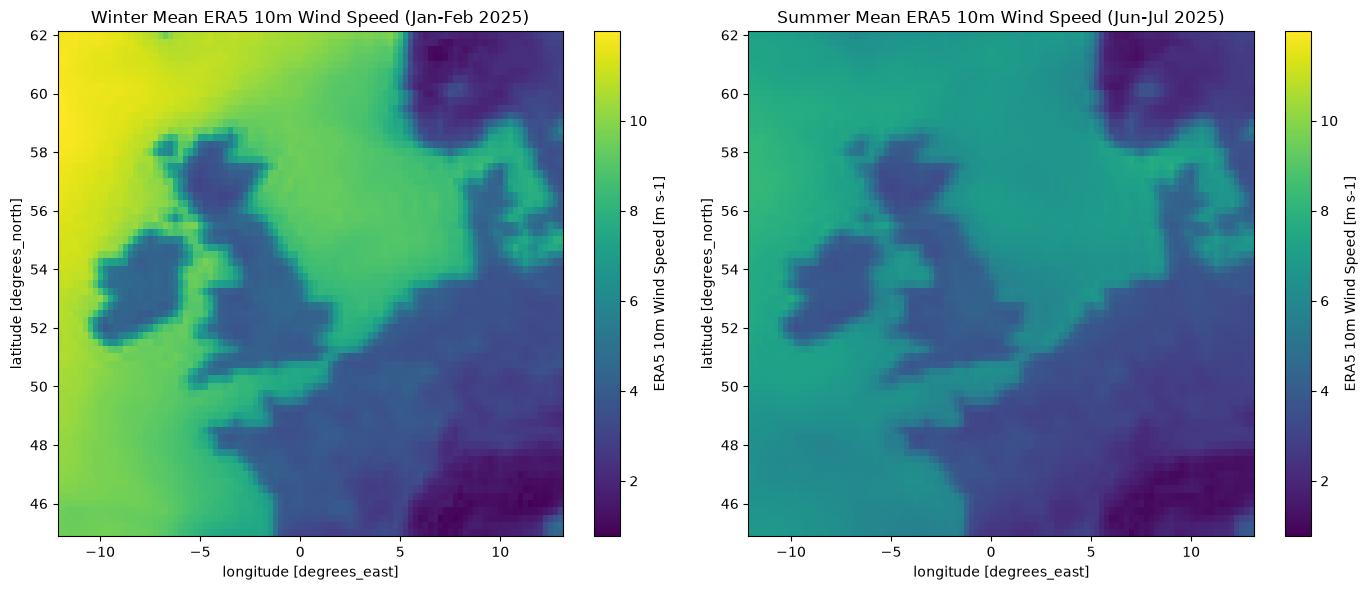

In [83]:
# ==============================
# --- North Western Europe ---
# ==============================

latitude = slice(62, 45)
longitude = slice(-12, 13)
variable = "ws10_era5"

nw_europe, winter, summer = select_region(ds, latitude, longitude, variable)

In [ ]:
#winter.to_netcdf("GCE Indicators/Quality Assessment/Offshore Wind Assessment/Data/ERA5_WS10_nweurope_winter.nc")
#summer.to_netcdf("GCE Indicators/Quality Assessment/Offshore Wind Assessment/Data/ERA5_WS10_nweurope_summer.nc")

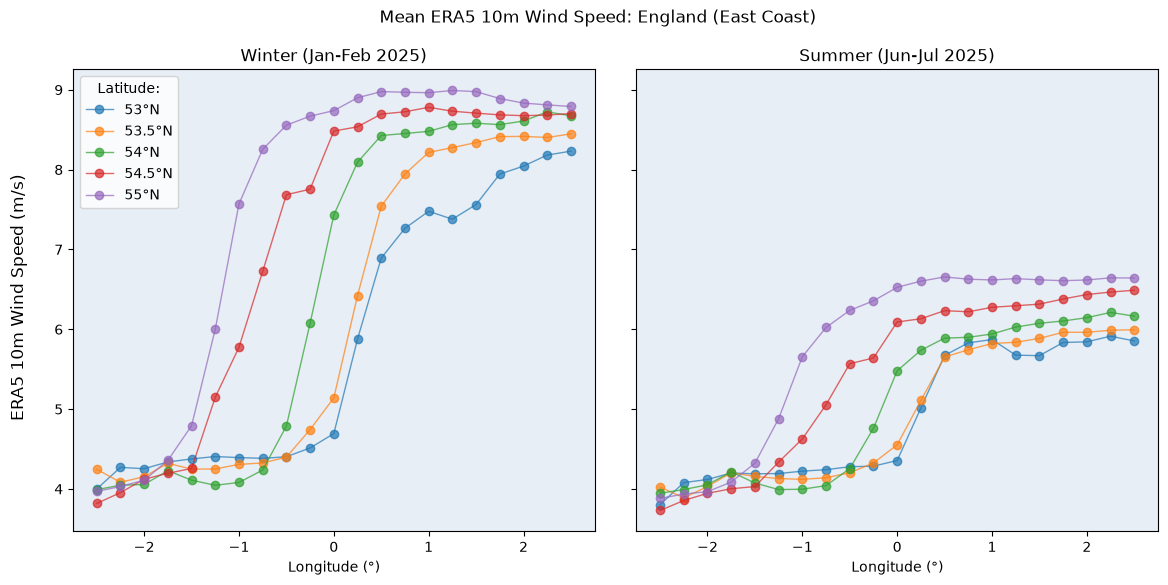

In [72]:
# ----- England (East Coast) -----

location = "England (East Coast)"

latitude = [53, 53.5, 54, 54.5, 55]
longitude = slice(-2.5, 2.5)
variable = "ws10_era5"

nw_europe_eng_E = plot_transects(winter, summer, latitude, longitude, variable, location)

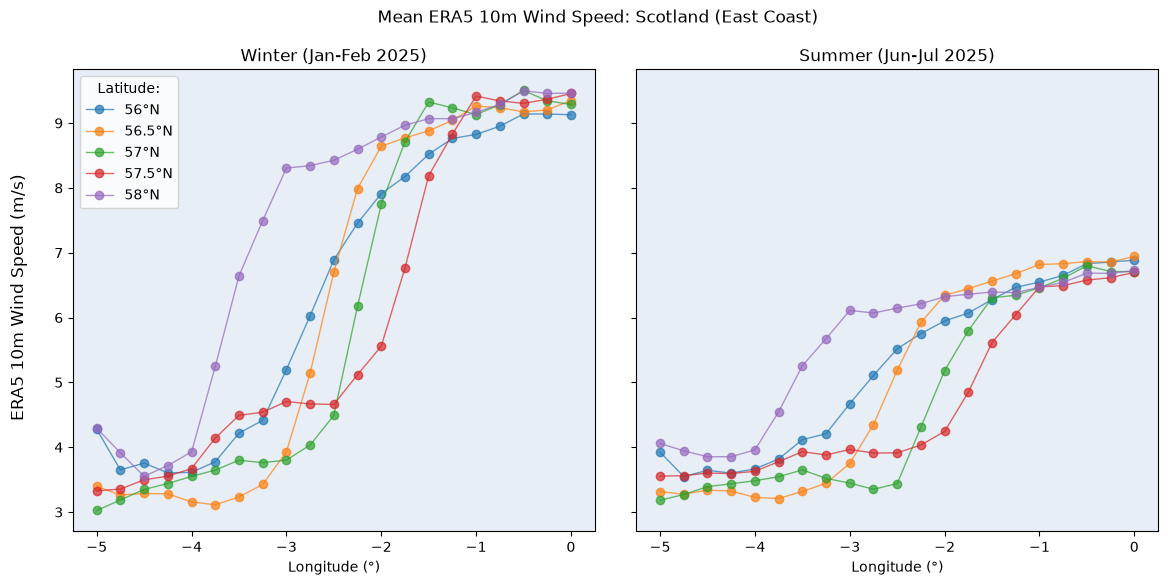

In [73]:
# ----- Scotland (East Coast) -----

location = "Scotland (East Coast)"

latitude = [56, 56.5, 57, 57.5, 58]
longitude = slice(-5.0, 0)
variable = "ws10_era5"

nw_europe_scot_E = plot_transects(winter, summer, latitude, longitude, variable, location)

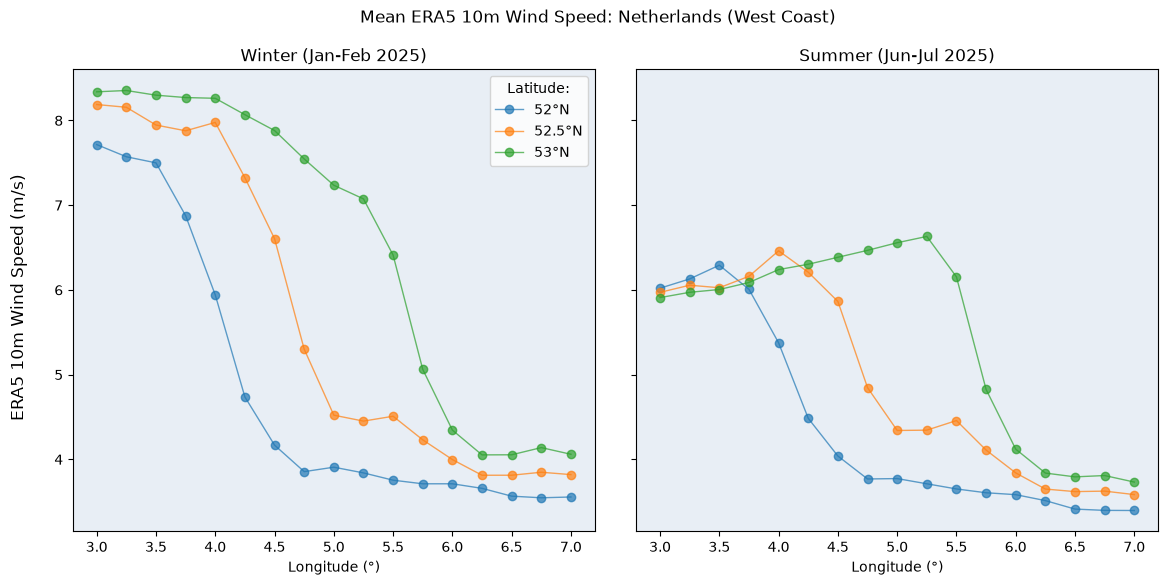

In [74]:
# ----- Netherlands (West Coast) -----

location = "Netherlands (West Coast)"

latitude = [52, 52.5, 53]
longitude = slice(3.0, 7.0)
variable = "ws10_era5"

nw_europe_nthlds_W = plot_transects(winter, summer, latitude, longitude, variable, location)

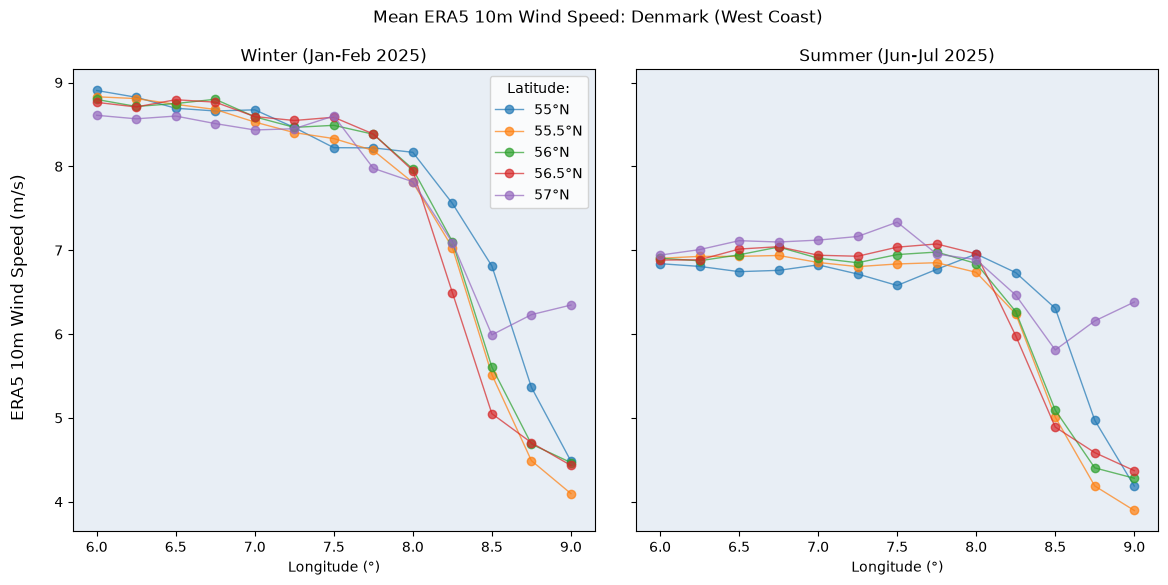

In [75]:
# ----- Denmark (West Coast) -----

location = "Denmark (West Coast)"

latitude = [55, 55.5, 56, 56.5, 57]
longitude = slice(6.0, 9.0)
variable = "ws10_era5"

nw_europe_dnmk_W = plot_transects(winter, summer, latitude, longitude, variable, location)

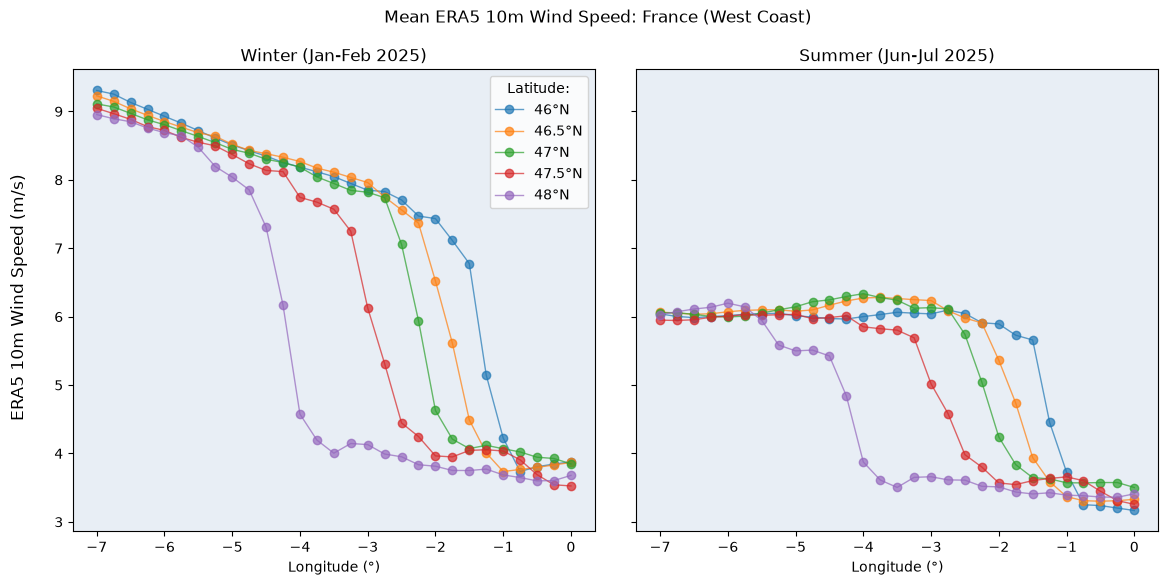

In [76]:
# ----- France (West Coast) -----

location = "France (West Coast)"

latitude = [46, 46.5, 47, 47.5, 48]
longitude = slice(-7.0, 0)
variable = "ws10_era5"

nw_europe_fr_W = plot_transects(winter, summer, latitude, longitude, variable, location)

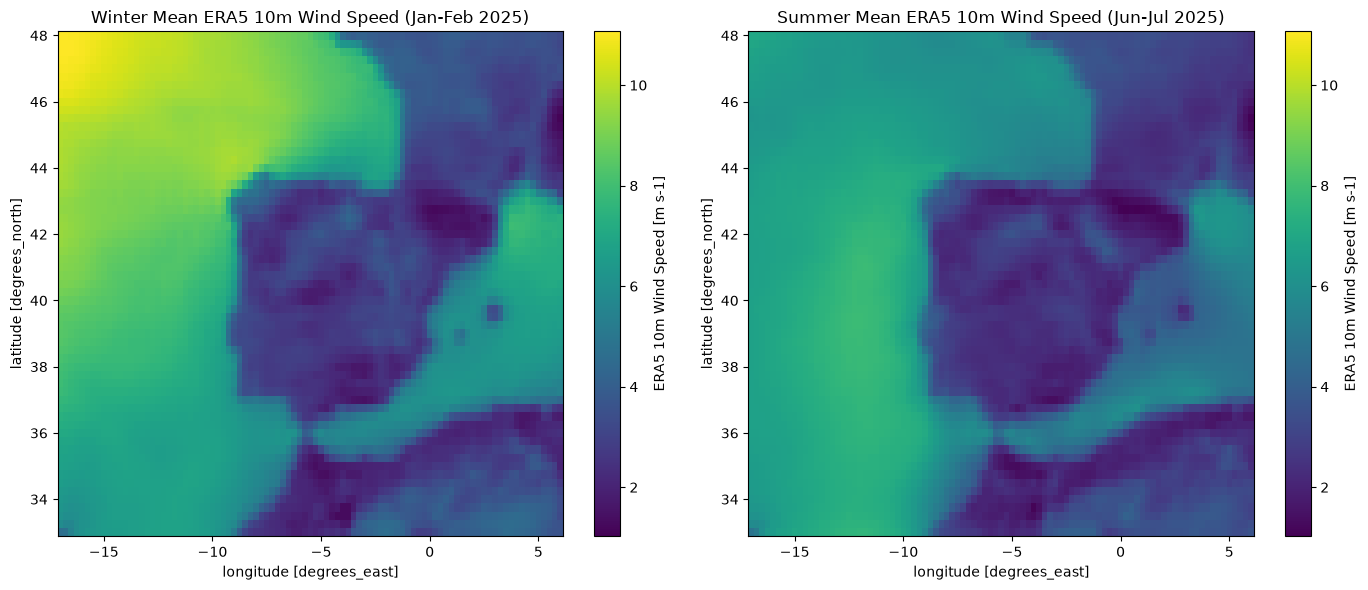

In [77]:
# ==============================
# --- Iberian Peninsula ---
# ==============================

latitude = slice(48, 33)
longitude = slice(-17, 6)
variable = "ws10_era5"

ib_pnsla, winter, summer = select_region(ds, latitude, longitude, variable)

In [ ]:
#winter.to_netcdf("GCE Indicators/Quality Assessment/Offshore Wind Assessment/Data/ERA5_WS10_ibpnsla_winter.nc")
#summer.to_netcdf("GCE Indicators/Quality Assessment/Offshore Wind Assessment/Data/ERA5_WS10_ibpnsla_summer.nc")

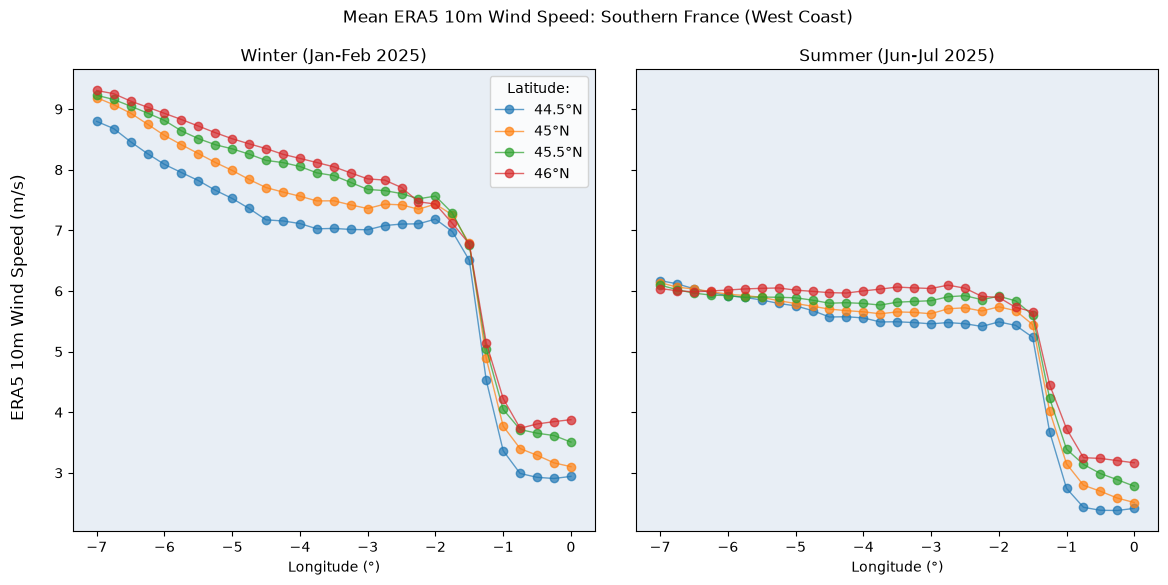

In [78]:
# ----- Southern France (West Coast) -----

location = "Southern France (West Coast)"

latitude = [44.5, 45, 45.5, 46]
longitude = slice(-7.0, 0)
variable = "ws10_era5"

ib_pnsla_sthfr_W = plot_transects(winter, summer, latitude, longitude, variable, location)

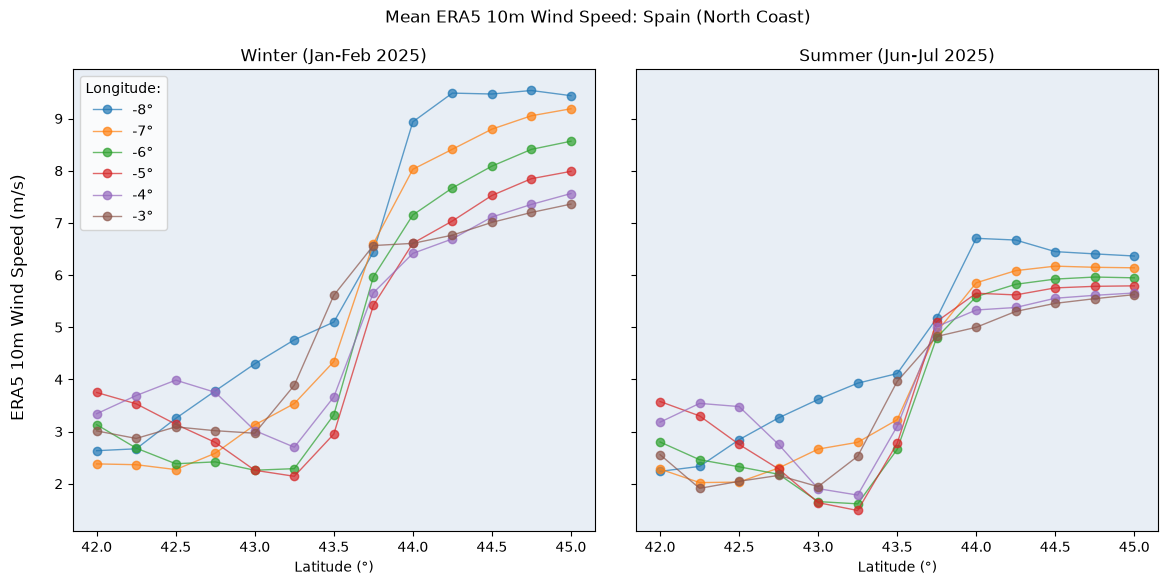

In [79]:
# ----- Northern Spain (North Coast) -----

location = "Spain (North Coast)"

latitude = slice(45, 42)
longitude = [-8, -7, -6, -5, -4, -3]
variable = "ws10_era5"

ib_pnsla_sp_N = plot_transects(winter, summer, latitude, longitude, variable, location)

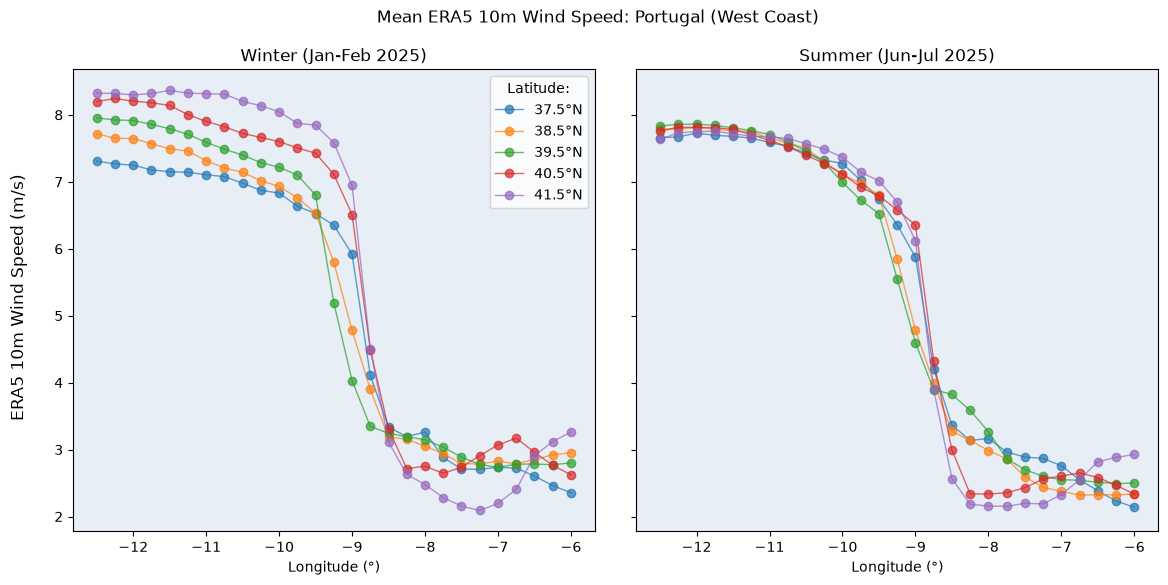

In [80]:
# ----- Portugal (West Coast) -----

location = "Portugal (West Coast)"

latitude = [37.5, 38.5, 39.5, 40.5, 41.5]
longitude = slice(-12.5, -6)
variable = "ws10_era5"

ib_pnsla_prtgl_W = plot_transects(winter, summer, latitude, longitude, variable, location)